# Лабораторная работа №1. Регрессия

Цель: предсказать качество красного вина и сравнить линейную регрессию, случайный лес и градиентный бустинг.

Данные: [Wine Quality, UCI](https://doi.org/10.24432/C56S3T)

## 1. Импорт библиотек

In [1]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

## 2. Загрузка данных

В каждой строке записаны 11 химических показателей вина и оценка quality. Оценки целые, но модель регрессии может давать дробный прогноз.

In [2]:
filename = 'winequality-red.csv'
local_csv = next((p for p in (Path(filename), Path('regression') / filename) if p.is_file()), None)

if local_csv is None:
    url = 'https://archive.ics.uci.edu/static/public/186/wine+quality.zip'
    with urlopen(url, timeout=45) as response:
        archive_bytes = response.read()
    with ZipFile(BytesIO(archive_bytes)) as archive:
        data = pd.read_csv(archive.open(filename), sep=';')
    print('Данные загружены из UCI')
else:
    data = pd.read_csv(local_csv, sep=';')
    print(f'Данные прочитаны из {local_csv}')

print(f'Размер: {data.shape[0]} строк, {data.shape[1]} столбцов')
print(f'Пропусков: {data.isna().sum().sum()}; полных повторов: {data.duplicated().sum()}')
display(data.head())

Данные прочитаны из winequality-red.csv
Размер: 1599 строк, 12 столбцов
Пропусков: 0; полных повторов: 240


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Пропусков нет, все признаки числовые. Есть 240 повторяющихся строк.

## 3. Разбиение данных

Около 80% данных оставлю для обучения, 20% — для теста. Одинаковые наборы признаков объединяю в группы, чтобы копии одного образца не попали и в train, и в test. Поэтому доля тестовых строк может немного отличаться от 20%. Для повторяемости задаю random_state=42.

Модель выберу по кросс-валидации на train. Если постоянно подбирать модель по одному тесту, можно подстроиться под него и получить слишком оптимистичную оценку.

In [3]:
X = data.drop(columns='quality')
y = data['quality']
groups = pd.util.hash_pandas_object(X, index=False)

split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(split.split(X, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_groups = groups.iloc[train_idx]
assert set(train_groups).isdisjoint(groups.iloc[test_idx])

print(f'Train: {len(X_train)} строк; test: {len(X_test)} строк')
print(f'Уникальных наборов признаков: {groups.nunique()}')

Train: 1279 строк; test: 320 строк
Уникальных наборов признаков: 1359


## 4. Анализ данных

Посмотрю распределение оценок и связь признаков с качеством на обучающей выборке.

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1279.0,8.3177,1.7526,4.6000,7.1000,7.9000,9.2000,15.6000
volatile acidity,1279.0,0.5295,0.1815,0.1200,0.3900,0.5200,0.6400,1.5800
citric acid,1279.0,0.2704,0.1956,0.0000,0.0900,0.2500,0.4300,1.0000
residual sugar,1279.0,2.5452,1.4545,0.9000,1.9000,2.2000,2.6000,15.5000
chlorides,1279.0,0.0879,0.0480,0.0120,0.0710,0.0800,0.0900,0.6110
free sulfur dioxide,1279.0,15.7834,10.4504,1.0000,7.0000,13.0000,22.0000,72.0000
total sulfur dioxide,1279.0,46.5442,33.1568,6.0000,22.0000,38.0000,62.0000,289.0000
density,1279.0,0.9968,0.0019,0.9901,0.9957,0.9968,0.9979,1.0037
pH,1279.0,3.3112,0.1523,2.7400,3.2100,3.3100,3.4000,4.0100
sulphates,1279.0,0.6570,0.1671,0.3300,0.5500,0.6200,0.7300,2.0000


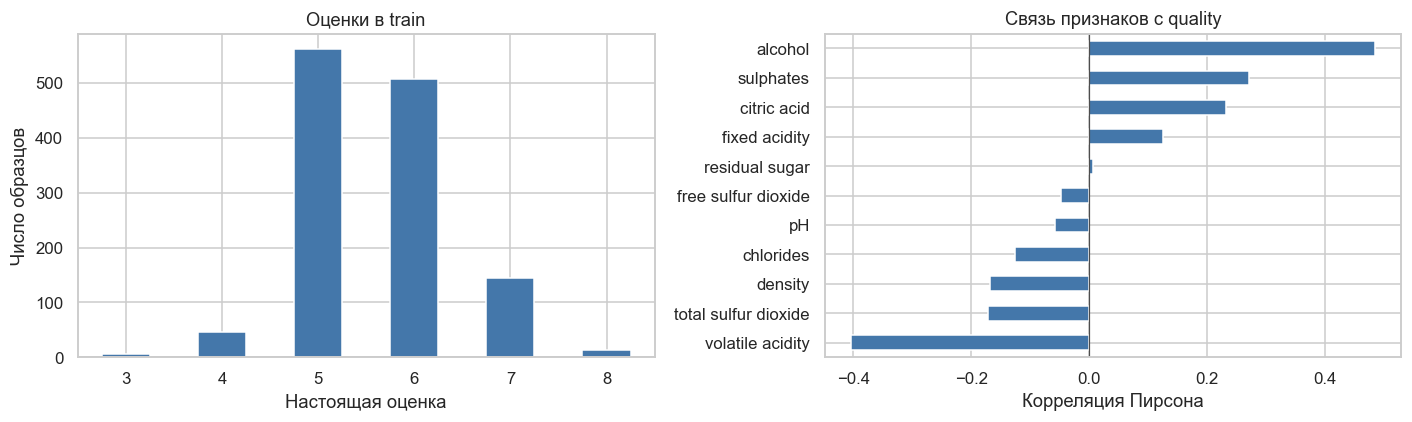

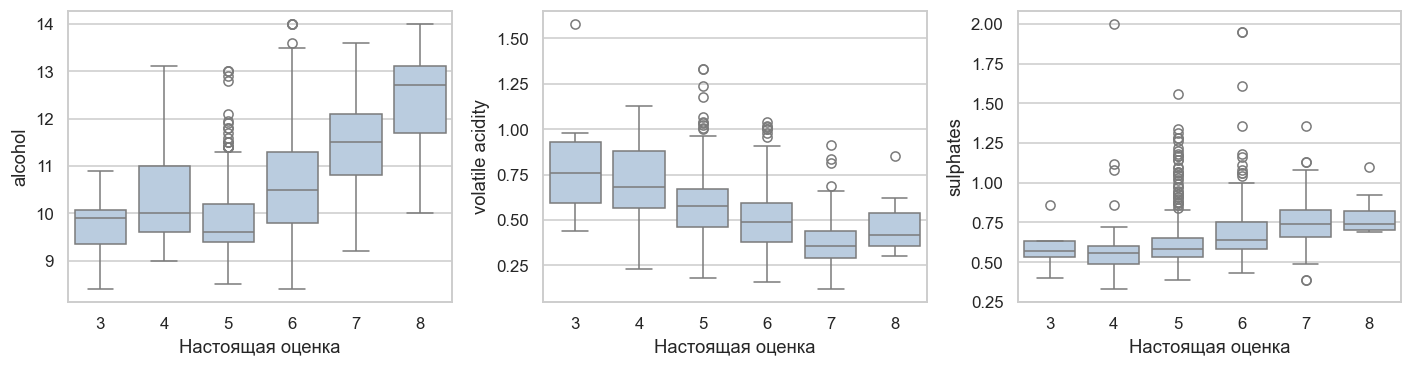

In [4]:
train_data = X_train.assign(quality=y_train)
display(train_data.describe().T.round(4))
counts = y_train.value_counts().sort_index()
correlations = train_data.corr()['quality'].drop('quality').sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts.plot.bar(ax=axes[0], rot=0, color='#4477AA')
axes[0].set(title='Оценки в train', xlabel='Настоящая оценка', ylabel='Число образцов')
correlations.plot.barh(ax=axes[1], color='#4477AA')
axes[1].axvline(0, color='0.3', linewidth=0.8)
axes[1].set(title='Связь признаков с quality', xlabel='Корреляция Пирсона')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for feature, ax in zip(['alcohol', 'volatile acidity', 'sulphates'], axes):
    sns.boxplot(data=train_data, x='quality', y=feature, ax=ax, color='#B4CCE5')
    ax.set_xlabel('Настоящая оценка')
plt.tight_layout()
plt.show()

Чаще всего встречаются оценки 5 и 6: 1068 из 1279 строк. Оценок 3 и 8 мало, поэтому предсказывать их будет сложнее. С качеством положительно связан алкоголь (0,485), отрицательно — летучая кислотность (-0,404). Группы на графиках пересекаются, поэтому одного признака недостаточно. Оставлю все признаки: слабая корреляция не означает, что признак бесполезен.

## 5. Метрики и baseline

MAE — средняя абсолютная ошибка. RMSE — корень из средней квадратичной ошибки. Обе метрики измеряются в баллах quality, меньше — лучше. RMSE сильнее реагирует на большие промахи: при ошибках 0 и 2 MAE равна 1, а RMSE — 1,41.

Baseline всегда предсказывает среднюю оценку по train. Среднее выбрано потому, что оно даёт минимальную квадратичную ошибку среди постоянных прогнозов.

In [5]:
def metrics(actual, predicted):
    return {
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'MAE': mean_absolute_error(actual, predicted),
    }

baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
print(f'Постоянный прогноз baseline: {baseline.constant_.item():.4f}')

Постоянный прогноз baseline: 5.6044


## 6. Модели

Линейная регрессия складывает признаки с весами. Перед ней стандартизирую данные, чтобы сравнивать коэффициенты. Масштабирование обучается внутри Pipeline только на обучающих данных.

Случайный лес усредняет прогнозы 300 деревьев. Минимум два образца в листе ограничивают запоминание отдельных строк. Бустинг тоже использует 300 деревьев, но строит их по очереди, исправляя ошибки предыдущего прогноза. Для деревьев масштабирование не требуется.

In [6]:
models = {
    'Baseline': baseline,
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Random Forest': RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=1,
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3,
        min_samples_leaf=3, random_state=SEED,
    ),
}

## 7. Кросс-валидация

Разобью train на пять частей. Каждый раз обучаю модель на четырёх, проверяю на оставшейся. Повторы держу вместе. Разбиения одинаковые для всех моделей, параметры фиксированы. Выбираю минимальный средний RMSE.

In [7]:
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train, groups=train_groups))
cv_rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=folds,
        scoring={'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error'},
        return_train_score=True, error_score='raise',
    )
    cv_rows.append({
        'Модель': name,
        'Train RMSE': -scores['train_rmse'].mean(),
        'CV RMSE': -scores['test_rmse'].mean(),
        'CV RMSE std': scores['test_rmse'].std(),
        'CV MAE': -scores['test_mae'].mean(),
    })

cv_results = pd.DataFrame(cv_rows).set_index('Модель')
selected = cv_results['CV RMSE'].idxmin()
display(cv_results.round(4))
print('Модель, выбранная по CV:', selected)

,Train RMSE,CV RMSE,CV RMSE std,CV MAE
Модель,,,,
Baseline,0.7946,0.7939,0.0373,0.6765
Linear Regression,0.6258,0.6370,0.0308,0.4931
Random Forest,0.2709,0.6234,0.0482,0.4782
Gradient Boosting,0.3965,0.6392,0.0460,0.4936


Модель, выбранная по CV: Random Forest


Лучший средний RMSE у леса: 0,6234. На обучающих частях ошибка заметно меньше (0,2709), что говорит о переобучении. Но на проверочных частях лес всё равно оказался лучшим из этих моделей.

## 8. Сравнение на тесте

Обучу модели на всём train и проверю на одном test. Этот тест уже смотрел в предыдущей версии работы, поэтому он не является новой независимой проверкой. В этой версии модель выбираю по CV.

,RMSE,MAE
Модель,,
Baseline,0.8587,0.7204
Linear Regression,0.7170,0.5554
Random Forest,0.6885,0.5323
Gradient Boosting,0.7206,0.5637


RMSE выбранной модели: 0.6885


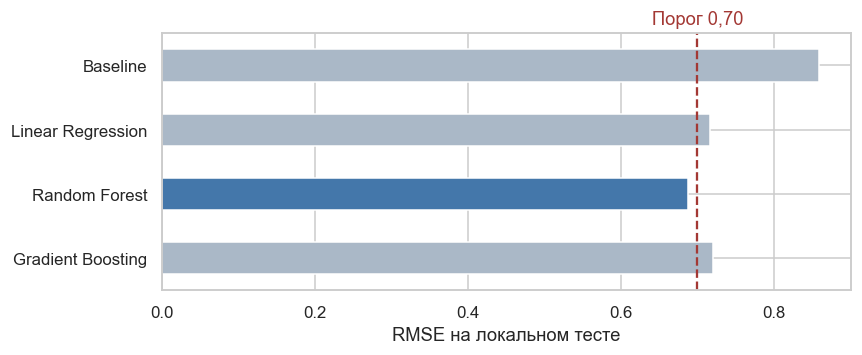

In [8]:
fitted_models = {}
predictions = {}
for name, model in models.items():
    fitted_models[name] = clone(model).fit(X_train, y_train)
    predictions[name] = fitted_models[name].predict(X_test)

results = pd.DataFrame.from_dict(
    {name: metrics(y_test, pred) for name, pred in predictions.items()}, orient='index',
).rename_axis('Модель')
display(results.round(4))
print(f'RMSE выбранной модели: {results.loc[selected, "RMSE"]:.4f}')

fig, ax = plt.subplots(figsize=(8, 3.4))
colors = ['#4477AA' if name == selected else '#AAB8C7' for name in results.index]
results['RMSE'].plot.barh(ax=ax, color=colors)
ax.axvline(0.70, linestyle='--', color='#A33834')
ax.text(0.70, 1.02, 'Порог 0,70', transform=ax.get_xaxis_transform(),
        ha='center', va='bottom', color='#A33834')
ax.set(xlabel='RMSE на локальном тесте', ylabel='')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Все три модели лучше baseline с RMSE 0,8587. У выбранного леса RMSE 0,6885 и MAE 0,5323. Он учитывает нелинейные связи и усредняет деревья, что здесь помогло больше, чем линейная модель. Бустинг с заданными параметрами показал результат, близкий к линейной регрессии.

## 9. Важность признаков

У линейной модели сравню коэффициенты после стандартизации: они показывают изменение прогноза при изменении признака на одно стандартное отклонение, если остальные признаки фиксированы. У леса и бустинга посмотрю feature_importances_ — насколько признаки полезны при разбиении деревьев.

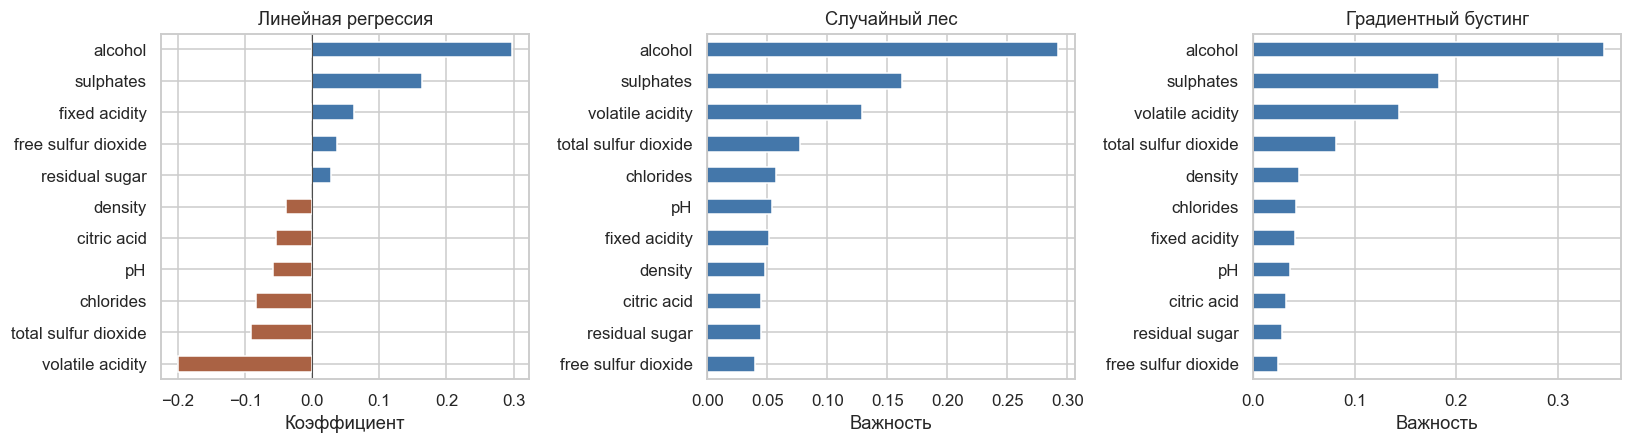

Линейная модель: alcohol, volatile acidity, sulphates
Лес: alcohol, sulphates, volatile acidity
Бустинг: alcohol, sulphates, volatile acidity


In [9]:
linear = fitted_models['Linear Regression'].named_steps['linearregression']
coefficients = pd.Series(linear.coef_, index=X.columns)
forest_importance = pd.Series(fitted_models['Random Forest'].feature_importances_, index=X.columns)
boosting_importance = pd.Series(fitted_models['Gradient Boosting'].feature_importances_, index=X.columns)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, values, title, xlabel in zip(
    axes, [coefficients, forest_importance, boosting_importance],
    ['Линейная регрессия', 'Случайный лес', 'Градиентный бустинг'],
    ['Коэффициент', 'Важность', 'Важность'],
):
    ordered = values.sort_values()
    ordered.plot.barh(ax=ax, color=['#AA6244' if x < 0 else '#4477AA' for x in ordered])
    ax.axvline(0, color='0.3', linewidth=0.7)
    ax.set(title=title, xlabel=xlabel)
plt.tight_layout()
plt.show()

print('Линейная модель:', ', '.join(coefficients.abs().nlargest(3).index))
print('Лес:', ', '.join(forest_importance.nlargest(3).index))
print('Бустинг:', ', '.join(boosting_importance.nlargest(3).index))

Во всех моделях важны алкоголь, летучая кислотность и сульфаты. У линейной регрессии коэффициенты равны 0,298, -0,200 и 0,164. У деревьев после алкоголя идут сульфаты, затем летучая кислотность. Это согласуется с анализом данных.

Важность не доказывает причинную связь: признаки зависят друг от друга, а данные не показывают результат отдельного изменения одного показателя.

## 10. Анализ ошибок

Ошибка — это прогноз минус настоящая оценка. Положительное значение означает, что модель завысила качество.

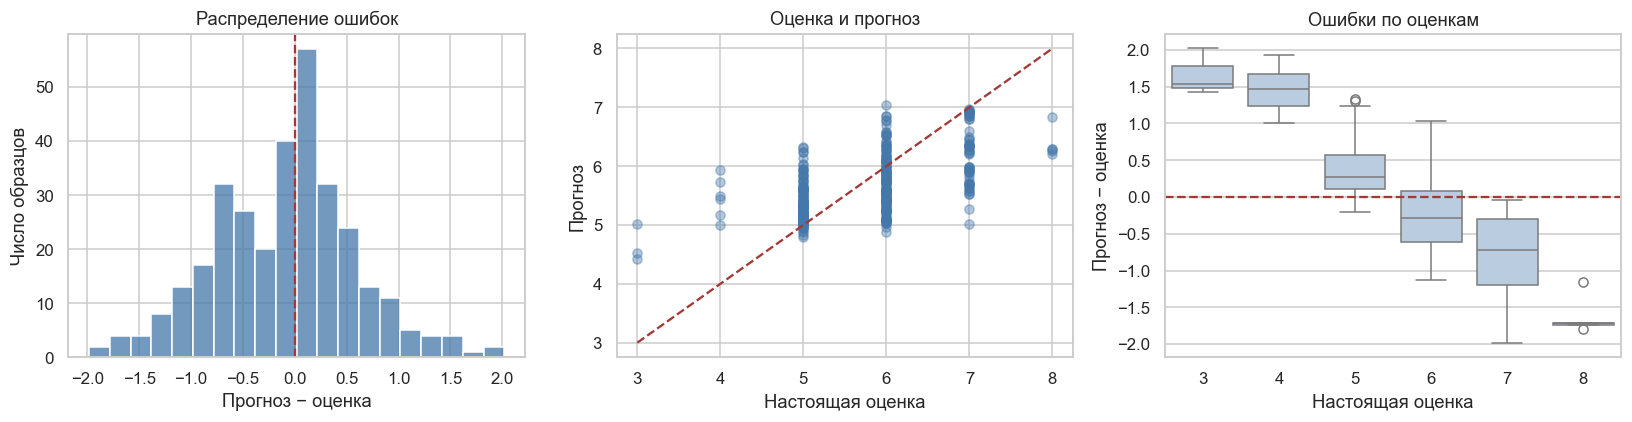

In [10]:
errors = pd.DataFrame({'quality': y_test, 'prediction': predictions[selected]})
errors['error'] = errors['prediction'] - errors['quality']
errors['abs_error'] = errors['error'].abs()
errors['squared_error'] = errors['error'] ** 2

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(errors['error'], bins=20, ax=axes[0], color='#4477AA')
axes[0].axvline(0, color='#A33834', linestyle='--')
axes[0].set(title='Распределение ошибок', xlabel='Прогноз − оценка', ylabel='Число образцов')
axes[1].scatter(errors['quality'], errors['prediction'], alpha=0.4, color='#4477AA')
axes[1].plot([3, 8], [3, 8], color='#A33834', linestyle='--')
axes[1].set(title='Оценка и прогноз', xlabel='Настоящая оценка', ylabel='Прогноз')
sns.boxplot(data=errors, x='quality', y='error', ax=axes[2], color='#B4CCE5')
axes[2].axhline(0, color='#A33834', linestyle='--')
axes[2].set(title='Ошибки по оценкам', xlabel='Настоящая оценка', ylabel='Прогноз − оценка')
plt.tight_layout()
plt.show()

In [11]:
by_quality = errors.groupby('quality').agg(
    count=('error', 'size'), mean_error=('error', 'mean'),
    MAE=('abs_error', 'mean'), MSE=('squared_error', 'mean'),
)
by_quality['RMSE'] = np.sqrt(by_quality.pop('MSE'))
display(by_quality.round(3))

worst = errors.nlargest(5, 'abs_error')
features = ['alcohol', 'volatile acidity', 'sulphates', 'chlorides']
print('Самые крупные ошибки, с индексами строк исходного CSV:')
display(worst[['quality', 'prediction', 'error']].join(X_test[features]).round(3))

,count,mean_error,MAE,RMSE
quality,,,,
3,3,1.659,1.659,1.679
4,6,1.463,1.463,1.496
5,120,0.357,0.370,0.493
6,131,-0.257,0.465,0.547
7,55,-0.785,0.785,0.934
8,5,-1.623,1.623,1.639


Самые крупные ошибки, с индексами строк исходного CSV:


,quality,prediction,error,alcohol,volatile acidity,sulphates,chlorides
1374,3,5.018,2.018,9.8,0.815,0.51,0.267
7,7,5.019,-1.981,10.0,0.650,0.47,0.065
1124,4,5.928,1.928,11.5,0.580,0.62,0.096
440,8,6.205,-1.795,9.8,0.310,0.82,0.072
1090,8,6.262,-1.738,11.8,0.260,0.63,0.083


Для оценок 5 и 6 RMSE равна примерно 0,49 и 0,55, для 3 и 8 — 1,68 и 1,64. Лес завышает низкие оценки и занижает высокие. В train всего 7 образцов с оценкой 3 и 13 с оценкой 8, поэтому таких примеров для обучения мало.

В строке 1374 оценка 3, а прогноз 5,018. Несмотря на высокую летучую кислотность и хлориды, модель завысила оценку: возможно, ей не хватило похожих примеров.

В строке 7 оценка 7, прогноз 5,019. Алкоголь 10,0 и сульфаты 0,47 больше похожи на значения у вин со средними оценками. В строке 440 оценка 8, прогноз 6,205: при высоких сульфатах алкоголь всего 9,8. Эти сочетания могли затруднить прогноз. Это возможные объяснения, а не доказанные причины.

## 11. Вывод

По кросс-валидации выбрал случайный лес. На локальном тесте RMSE = 0,6885, то есть ниже требуемых 0,70. Самые полезные признаки — алкоголь, летучая кислотность и сульфаты. Больше всего ошибок на редких крайних оценках. Результат на скрытом тесте преподавателя пока неизвестен.

Версии для запуска: Python 3.9, NumPy 1.26.4, pandas 2.3.3, Matplotlib 3.9.4, seaborn 0.13.2, scikit-learn 1.6.1. Ячейки запускать сверху вниз.